In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# 데이터 로드

In [2]:
df_adrs = pd.read_excel(
    "1톤화물차_운송내역_copy.xlsx",
    sheet_name="납품지",
    header=0
)

df_log = pd.read_excel(
    "1톤화물차_운송내역_copy.xlsx",
    sheet_name="26년 통합데이터",
    header=0
)

# 편도·왕복: 0 -> 1
# 결측치 -> 0
trip_columns = ["편도", "왕복"]
df_log[trip_columns] = df_log[trip_columns].notna().astype(int)

# join
df_log = pd.merge(df_log, df_adrs, how="left", on="납품업체")

# 분석용 데이터
df = df_log.copy()
df["일자"] = pd.to_datetime(df["일자"])
df["수량(kg)"] = pd.to_numeric(df["수량(kg)"], errors="coerce")
df["금액(원)"] = pd.to_numeric(df["금액(원)"], errors="coerce")

# 원본시트와 순번의 조합을 하나의 용차 운행으로 정의
df["운행ID"] = (
    df["원본시트"].astype(str)
    + "-"
    + df["순번"].astype(str)
)

In [3]:
# # df['운행ID'].value_counts()
#
# df[df['운행ID'] == '26-송-3)-45']
# df[(df['원본시트'] == '26-송-3)') & (df['일자'] == '2026-03-20')]

# matplotlib 폰트

In [4]:
# 한글 폰트 설정
font_path = "/mnt/c/Windows/Fonts/malgun.ttf"

if not os.path.exists(font_path):
    raise FileNotFoundError(f"폰트 파일이 없습니다: {font_path}")

# 폰트 등록
fm.fontManager.addfont(font_path)
font_name = fm.FontProperties(fname=font_path).get_name()

# seaborn 설정 후 폰트 지정
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "font.family": font_name,
    "font.sans-serif": [font_name],
    "axes.unicode_minus": False,
})

print("설정된 폰트:", font_name)

설정된 폰트: Malgun Gothic


# 기초 분석

In [5]:
# 데이터 전처리: 운행 단위 데이터 생성
trip_df = (
    df.groupby(["운행ID", "일자"], as_index=False)
      .agg(
          운행유형=("왕복", lambda x: "왕복" if x.max() == 1 else "편도"),
          납품업체수=("납품업체", "nunique"),
          납품업체=("납품업체", lambda x: ", ".join(x.dropna().astype(str).unique())),
          수량_kg=("수량(kg)", "max"),
          운송비_원=("금액(원)", "max"),
      )
)

trip_df.head(3)

,운행ID,일자,운행유형,납품업체수,납품업체,수량_kg,운송비_원
0,26-송-1-1,2026-01-07,왕복,1,일산,2028.0,100000.0
1,26-송-1-10,2026-01-09,왕복,1,토마스,2154.0,120000.0
2,26-송-1-11,2026-01-09,왕복,1,극동,1690.5,100000.0


In [6]:
# 일별 사용량 요약
daily_summary = (
    trip_df.groupby("일자")
           .agg(
               용차사용대수=("운행ID", "nunique"),
               총수량_kg=("수량_kg", "sum"),
               총운송비_원=("운송비_원", "sum"),
               평균운송비_원=("운송비_원", "mean"),
               평균적재량_kg=("수량_kg", "mean"),
               방문업체수=("납품업체수", "sum"),
           )
           .reset_index()
)

daily_summary["대당평균운송비_원"] = (
    daily_summary["총운송비_원"]
    / daily_summary["용차사용대수"]
)

daily_summary.head(3)

,일자,용차사용대수,총수량_kg,총운송비_원,평균운송비_원,평균적재량_kg,방문업체수,대당평균운송비_원
0,2026-01-05,2,4285.5,190000.0,95000.000000,2142.750000,2,95000.000000
1,2026-01-06,3,5784.8,280000.0,93333.333333,1928.266667,3,93333.333333
2,2026-01-07,3,5823.5,390000.0,130000.000000,1941.166667,3,130000.000000


In [7]:
# 전체 요약:
overall_summary = pd.Series({
    "용차 운행 일수": daily_summary["일자"].nunique(),
    "총 용차 운행": trip_df["운행ID"].nunique(),
    "일평균 용차 운행": daily_summary["용차사용대수"].mean(),
    "일최대 용차 운행": daily_summary["용차사용대수"].max(),
    "총 운송비": trip_df["운송비_원"].sum(),
    "운행당 평균 운송비": trip_df["운송비_원"].mean(),
    "평균 적재량(kg)": trip_df["수량_kg"].mean(),
})

overall_summary.map(lambda x: f"{x:,.0f}")

용차 운행 일수             162
총 용차 운행              879
일평균 용차 운행              5
일최대 용차 운행             10
총 운송비         78,195,000
운행당 평균 운송비        89,060
평균 적재량(kg)         1,735
dtype: str

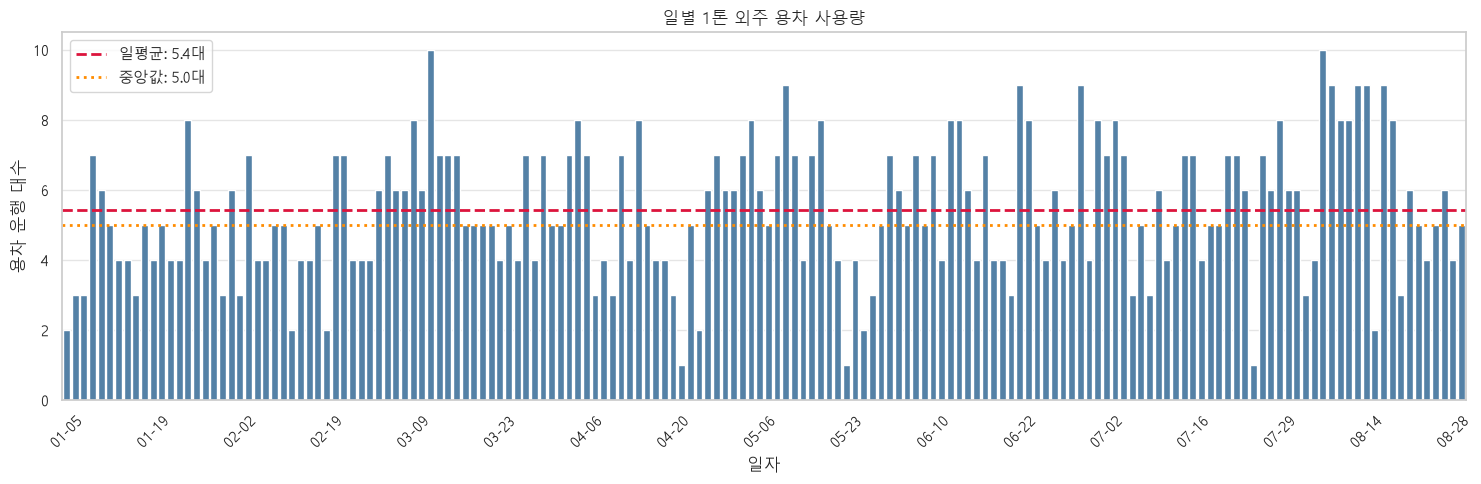

In [8]:
# 일별 1톤 외주 용차 사용량
fig, ax = plt.subplots(figsize=(15, 5))

sns.barplot(
    data=daily_summary,
    x="일자",
    y="용차사용대수",
    color="steelblue",
    ax=ax,
)

avg_trucks = daily_summary["용차사용대수"].mean()
median_trucks = daily_summary["용차사용대수"].median()
ax.axhline(
    avg_trucks, color="crimson", linestyle="--", linewidth=2,
    label=f"일평균: {avg_trucks:.1f}대"
)
ax.axhline(
    median_trucks, color="darkorange", linestyle=":", linewidth=2,
    label=f"중앙값: {median_trucks:.1f}대"
)
ax.legend()

ax.set_title("일별 1톤 외주 용차 사용량")
ax.set_xlabel("일자")
ax.set_ylabel("용차 운행 대수")

# 날짜가 너무 많을 경우 일부 눈금만 표시
tick_step = max(len(daily_summary) // 15, 1)
ax.set_xticks(range(0, len(daily_summary), tick_step))
ax.set_xticklabels(
    daily_summary["일자"].dt.strftime("%m-%d").iloc[::tick_step],
    rotation=45,
)

plt.tight_layout()
plt.show()

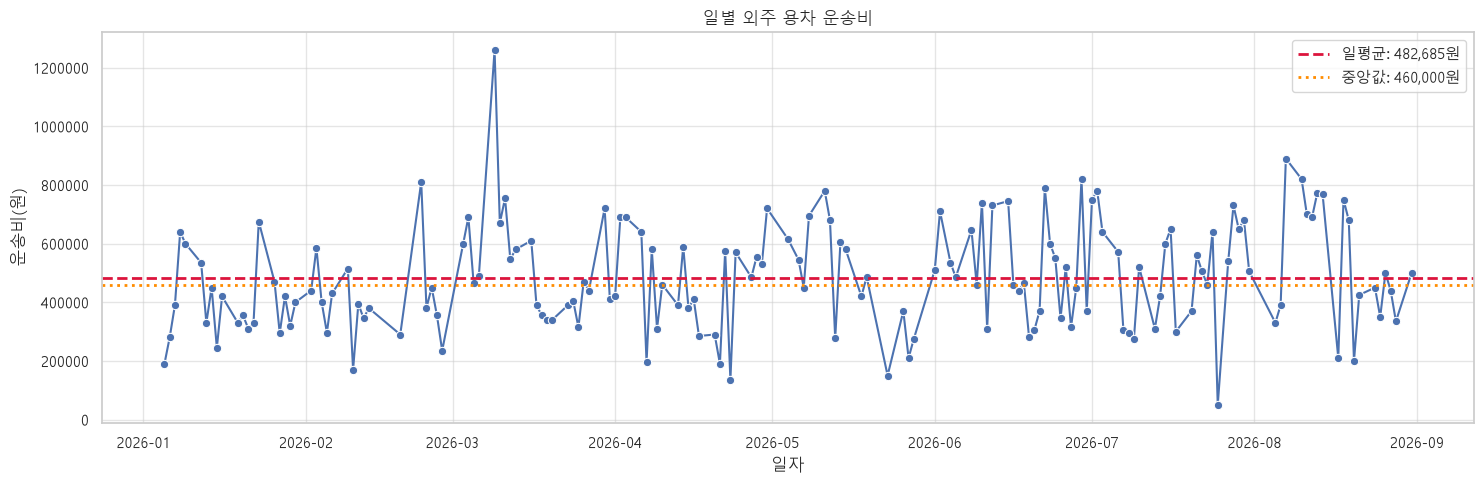

In [9]:
# 일별 운송비 추이
fig, ax = plt.subplots(figsize=(15, 5))

sns.lineplot(
    data=daily_summary,
    x="일자",
    y="총운송비_원",
    marker="o",
    ax=ax,
)

avg_cost = daily_summary["총운송비_원"].mean()
median_cost = daily_summary["총운송비_원"].median()
ax.axhline(
    avg_cost, color="crimson", linestyle="--", linewidth=2,
    label=f"일평균: {avg_cost:,.0f}원"
)
ax.axhline(
    median_cost, color="darkorange", linestyle=":", linewidth=2,
    label=f"중앙값: {median_cost:,.0f}원"
)
ax.legend()

ax.set_title("일별 외주 용차 운송비")
ax.set_xlabel("일자")
ax.set_ylabel("운송비(원)")
ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

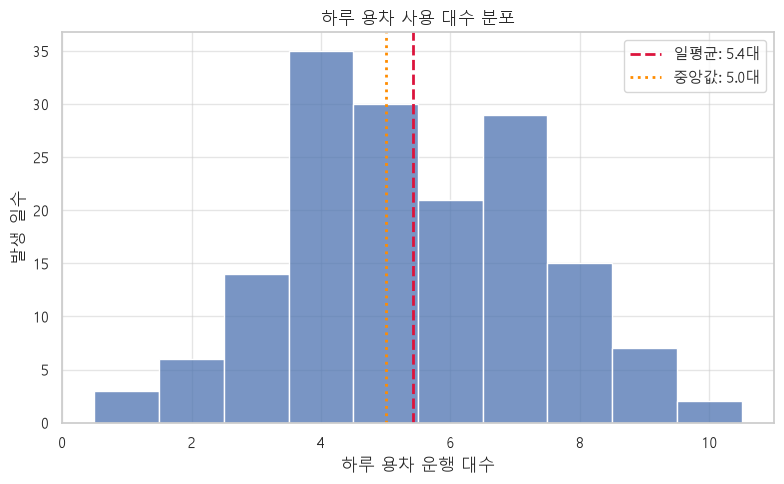

In [10]:
# 하루 사용 대수 분포
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=daily_summary,
    x="용차사용대수",
    discrete=True,
    binwidth=1,
    ax=ax,
)

avg_trucks = daily_summary["용차사용대수"].mean()
median_trucks = daily_summary["용차사용대수"].median()
ax.axvline(
    avg_trucks, color="crimson", linestyle="--", linewidth=2,
    label=f"일평균: {avg_trucks:.1f}대"
)
ax.axvline(
    median_trucks, color="darkorange", linestyle=":", linewidth=2,
    label=f"중앙값: {median_trucks:.1f}대"
)
ax.legend()

ax.set_title("하루 용차 사용 대수 분포")
ax.set_xlabel("하루 용차 운행 대수")
ax.set_ylabel("발생 일수")
plt.tight_layout()
plt.show()

운행당 평균 중량: 1,735.2 kg
운행당 중앙값: 1,898.0 kg
최소 중량: 0.0 kg
최대 중량: 3,309.8 kg


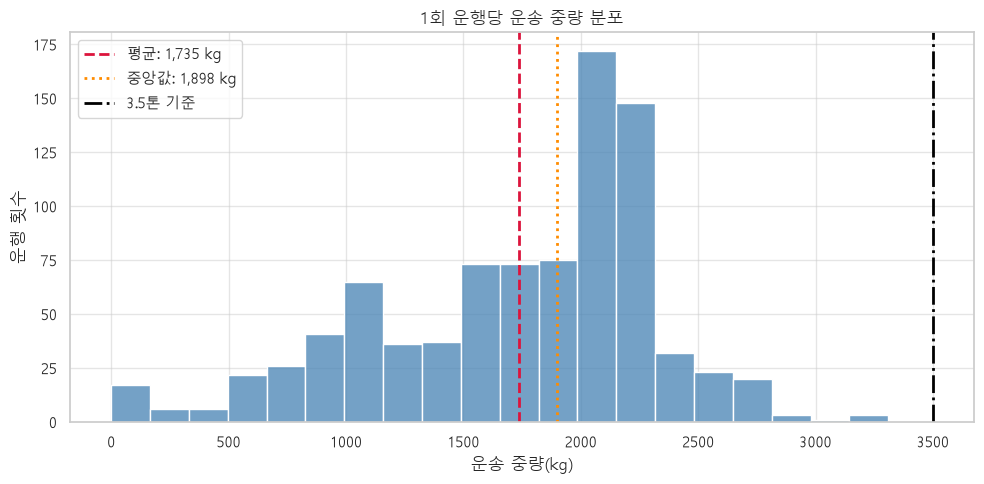

In [11]:
# 회당 중량
weight = trip_df["수량_kg"].dropna()

print(f"운행당 평균 중량: {weight.mean():,.1f} kg")
print(f"운행당 중앙값: {weight.median():,.1f} kg")
print(f"최소 중량: {weight.min():,.1f} kg")
print(f"최대 중량: {weight.max():,.1f} kg")
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    weight,
    bins=20,
    color="steelblue",
    edgecolor="white",
    ax=ax,
)

ax.axvline(
    weight.mean(),
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"평균: {weight.mean():,.0f} kg",
)

ax.axvline(
    weight.median(),
    color="darkorange",
    linestyle=":",
    linewidth=2,
    label=f"중앙값: {weight.median():,.0f} kg",
)

ax.axvline(
    3500,
    color="black",
    linestyle="-.",
    linewidth=2,
    label="3.5톤 기준",
)

ax.set_title("1회 운행당 운송 중량 분포")
ax.set_xlabel("운송 중량(kg)")
ax.set_ylabel("운행 횟수")
ax.legend()

plt.tight_layout()
plt.show()

# 업체별 분석

In [12]:
# 납품업체별 현황
# 동일 운행에서 같은 업체가 여러 행으로 나타나는 경우를 제거합니다.
vendor_trip = (
    df.groupby(["운행ID", "일자", "납품업체"], as_index=False)
      .agg(
          운송비_원=("금액(원)", "max"),
          운행중량_kg=("수량(kg)", "max"),
      )
)

# 다중 납품 운행의 운송비가 업체마다 중복 합산되지 않도록 균등 배분합니다.
vendor_trip["운행내업체수"] = (
    vendor_trip.groupby("운행ID")["납품업체"].transform("nunique")
)
vendor_trip["배분운송비_원"] = (
    vendor_trip["운송비_원"] / vendor_trip["운행내업체수"]
)

vendor_summary = (
    vendor_trip.groupby("납품업체")
               .agg(
                   운행횟수=("운행ID", "nunique"),
                   총운송비_원=("배분운송비_원", "sum"),
                   평균운송비_원=("배분운송비_원", "mean"),
                   평균운행중량_kg=("운행중량_kg", "mean"),
               )
               .sort_values("운행횟수", ascending=False)
)

vendor_summary.head(10).style.format({
    "운행횟수": "{:,.0f}",
    "총운송비_원": "{:,.0f}",
    "평균운송비_원": "{:,.0f}",
    "평균운행중량_kg": "{:,.1f}",
})

,운행횟수,총운송비_원,평균운송비_원,평균운행중량_kg
납품업체,,,,
일산,234,"19,062,222","81,462","2,048.5"
HG,155,"11,189,722","72,192","1,631.4"
명인,72,"4,082,500","56,701","1,952.4"
한미,51,"5,262,500","103,186","1,522.8"
동남,36,"4,087,500","113,542","1,336.3"
국보,34,"3,056,667","89,902","1,764.8"
승리,27,"838,333","31,049","1,616.3"
토마스,26,"2,321,667","89,295","1,683.1"
가양,22,"1,614,444","73,384","1,376.1"


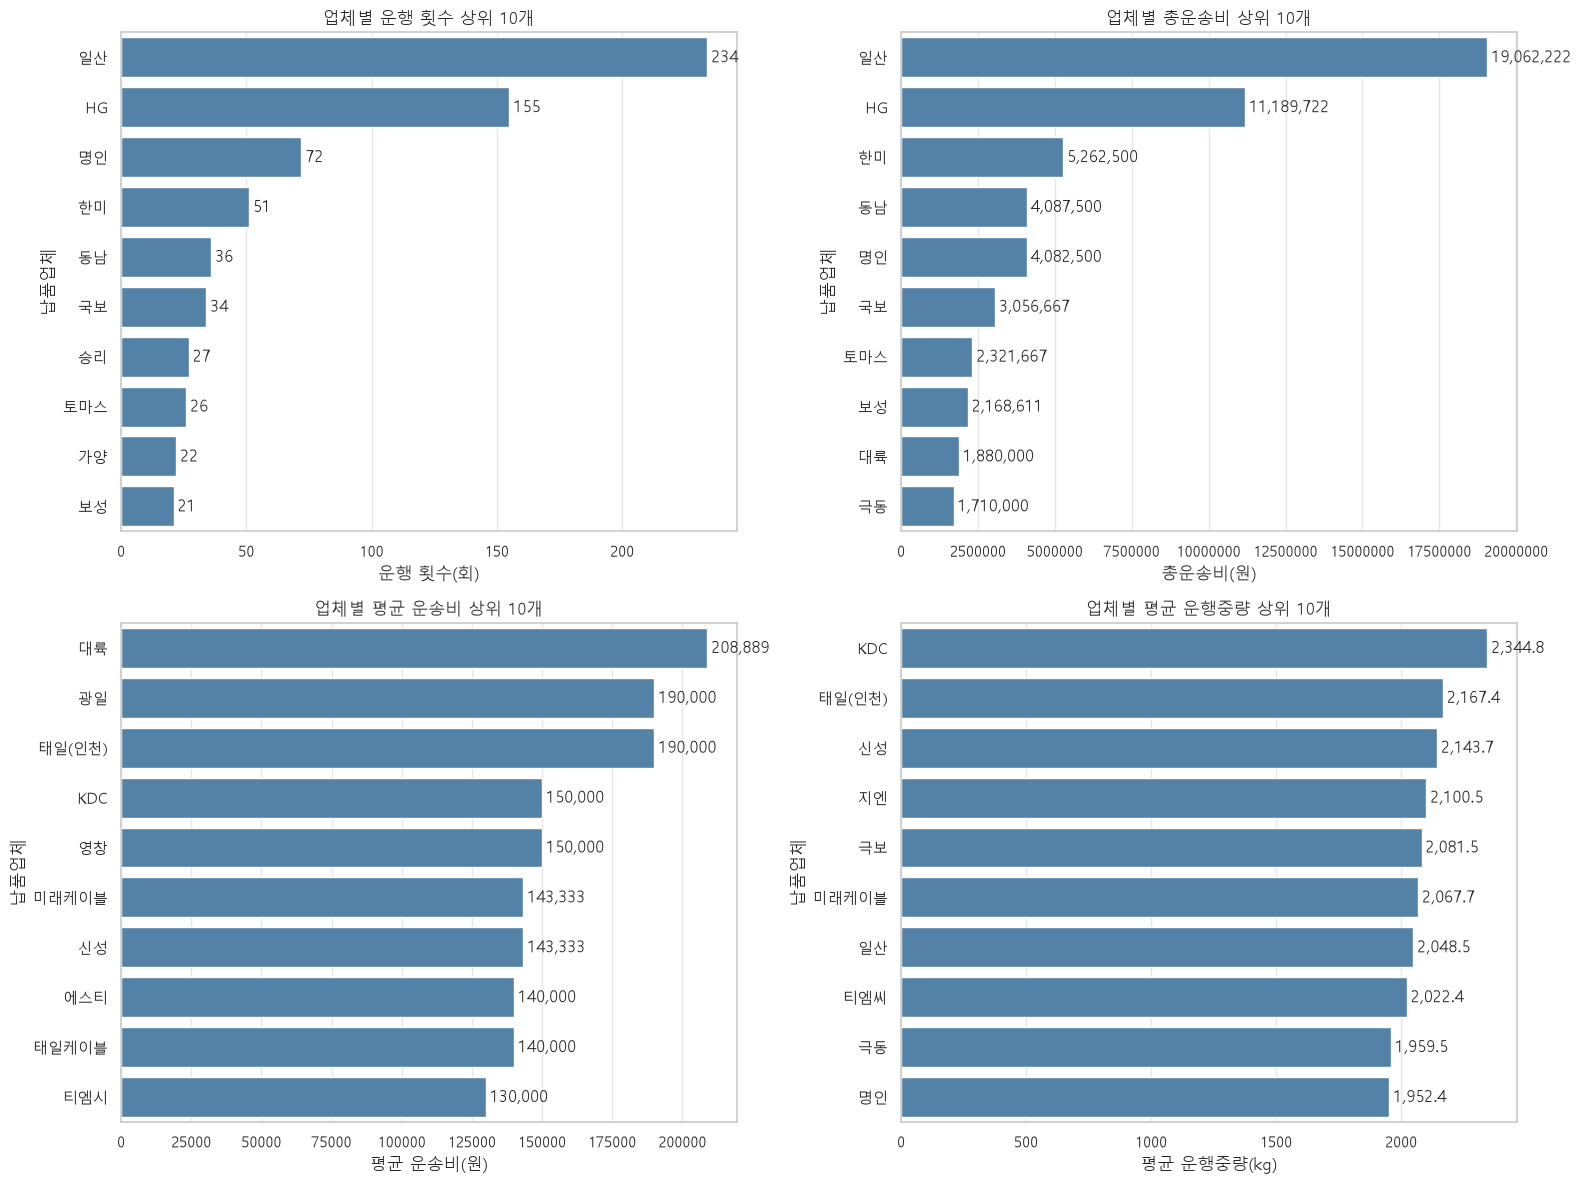

In [13]:
# 지표별 상위 10개 납품업체
metrics = {
    "운행횟수": ("운행 횟수(회)", "업체별 운행 횟수 상위 10개"),
    "총운송비_원": ("총운송비(원)", "업체별 총운송비 상위 10개"),
    "평균운송비_원": ("평균 운송비(원)", "업체별 평균 운송비 상위 10개"),
    "평균운행중량_kg": ("평균 운행중량(kg)", "업체별 평균 운행중량 상위 10개"),
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, (column, (xlabel, title)) in zip(axes.flat, metrics.items()):
    top10 = vendor_summary.nlargest(10, column).sort_values(column, ascending=False)
    sns.barplot(
        data=top10.reset_index(),
        x=column,
        y="납품업체",
        color="steelblue",
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("납품업체")
    ax.ticklabel_format(style="plain", axis="x")

    for container in ax.containers:
        labels = [f"{bar.get_width():,.1f}" if column == "평균운행중량_kg"
                  else f"{bar.get_width():,.0f}" for bar in container]
        ax.bar_label(container, labels=labels, padding=3)

plt.tight_layout()
plt.show()

In [14]:
df.columns

Index(['원본시트', '순번', '일자', '납품업체', '편도', '왕복', '수량(kg)', '금액(원)', '비고', '업체명',
       '소재지', '주소', '거리_km', '운행ID'],
      dtype='str')

# 통합 가능 조건 정의

보수적으로 다음 조건을 모두 만족하는 경우만 통합 후보로 분류한다.
* 운행일자가 동일하다.
* 서로 다른 외주 운행이다.
* 합계 중량이 6,000kg 이하이다.
* 업체가 같은 시·군·구이거나 인접 지역이다.
* 통합 운행거리가 개별 운행거리 합계보다 짧다.
* 납품시간, 상하차 조건에 충돌이 없다.
* 3.5톤 차량은 하루에 한 통합 노선만 담당한다고 가정한다.


[통합 배송 후보 요약]


,값,설명
전체 외주 운행 수,879.0,분석 기간에 실제로 사용한 1톤 외주 용차의 전체 운행 횟수
통합 배송 가능 일수,152.0,"같은 날·같은 권역·합계 6톤 이하 조건을 만족한 날짜 수(차량 1대, 하루 1회 기준)"
자가차량으로 대체 가능한 외주 운행 수,409.0,선택된 통합 노선에 포함되어 3.5톤 자가차량으로 대체 가능한 기존 외주 운행 횟수
필요한 자가차량 통합 운행 수,152.0,대체 후보 외주 운행을 처리하기 위해 3.5톤 자가차량이 운행해야 하는 횟수
전체 차량 움직임 감소 수,257.0,기존 외주 운행 수에서 자가차량 통합 운행 수를 뺀 순수 운행 횟수 감소분
전체 외주 운행 중 대체 후보 비율(%),46.5,전체 외주 운행 가운데 자가차량 통합 배송 후보에 포함된 운행의 비율
통합 노선 평균 적재율(%),81.5,"선택된 통합 노선별 합계 중량을 최대 적재량 6,000kg으로 나눈 비율의 평균"
통합 후보 기존 운송비 합계(원),"34,485,000.0",통합 후보에 포함된 기존 외주 운송비 합계이며 자가차량 운영비를 차감하기 전 금액


[날짜별 선택 후보 상세]


,일자,배송권역,기존운행ID,납품업체,소재지,기존외주운행수,통합운행수,차량움직임감소수,합계중량_kg,적재율_pct,기존운송비_원
0,2026-01-05 00:00:00,충북 중부권,"26-이-1-1, 26-이-1-2","토마스, 일산","충북 청주, 충북 음성",2,1,1,"4,285.5",71.4,"190,000"
1,2026-01-06 00:00:00,충북 중부권,"26-이-1-3, 26-이-1-4, 26-이-1-5","극동와이어, 극동, 일산","충북 청주, 충북 진천, 충북 음성",3,1,2,"5,784.8",96.4,"280,000"
2,2026-01-08 00:00:00,충북 중부권,"26-이-1-6, 26-이-1-7","극동와이어, 일산","충북 청주, 충북 음성",2,1,1,"3,720.0",62.0,"190,000"
3,2026-01-09 00:00:00,충북 중부권,"26-송-1-10, 26-송-1-11, 26-송-1-9","토마스, 극동, 일산","충북 청주, 충북 진천, 충북 음성",3,1,2,"5,724.5",95.4,"290,000"
4,2026-01-12 00:00:00,수도권 서남권,"26-송-1-12, 26-이-1-11","천하, 보성, 동남","서울 구로, 경기 인천, 경기 부천",2,1,1,"2,343.5",39.1,"295,000"
5,2026-01-13 00:00:00,충남 북부권,"26-이-1-14, 26-이-1-15","한미, 티엠씨",충남 천안,2,1,1,"3,417.7",57.0,"200,000"
6,2026-01-14 00:00:00,충남 북부권,"26-이-1-17, 26-이-1-18","티엠씨, 한미",충남 천안,2,1,1,"3,267.6",54.5,"190,000"
7,2026-01-15 00:00:00,충북 중부권,"26-송-1-17, 26-송-1-18","신일, 일산","충북 진천, 충북 음성",2,1,1,"3,167.0",52.8,"140,000"
8,2026-01-16 00:00:00,충남 북부권,"26-송-1-20, 26-송-1-21","티엠시, 한미",충남 천안,2,1,1,"3,624.1",60.4,"220,000"
9,2026-01-19 00:00:00,충북 중부권,"26-이-1-21, 26-이-1-22, 26-이-1-23","일산, 명인, 지앤",충북 음성,3,1,2,"5,469.7",91.2,"200,000"


,월,통합후보일수,대체가능외주운행수,차량움직임감소수,기존운송비_원,평균적재율_pct
0,2026-01,19,47,28,"3,975,000",73.8
1,2026-02,14,35,21,"2,835,000",77.6
2,2026-03,20,53,33,"5,035,000",82.4
3,2026-04,21,56,35,"4,250,000",80.0
4,2026-05,13,35,22,"2,860,000",83.8
5,2026-06,24,62,38,"5,395,000",78.2
6,2026-07,23,68,45,"5,510,000",87.7
7,2026-08,18,53,35,"4,625,000",87.8


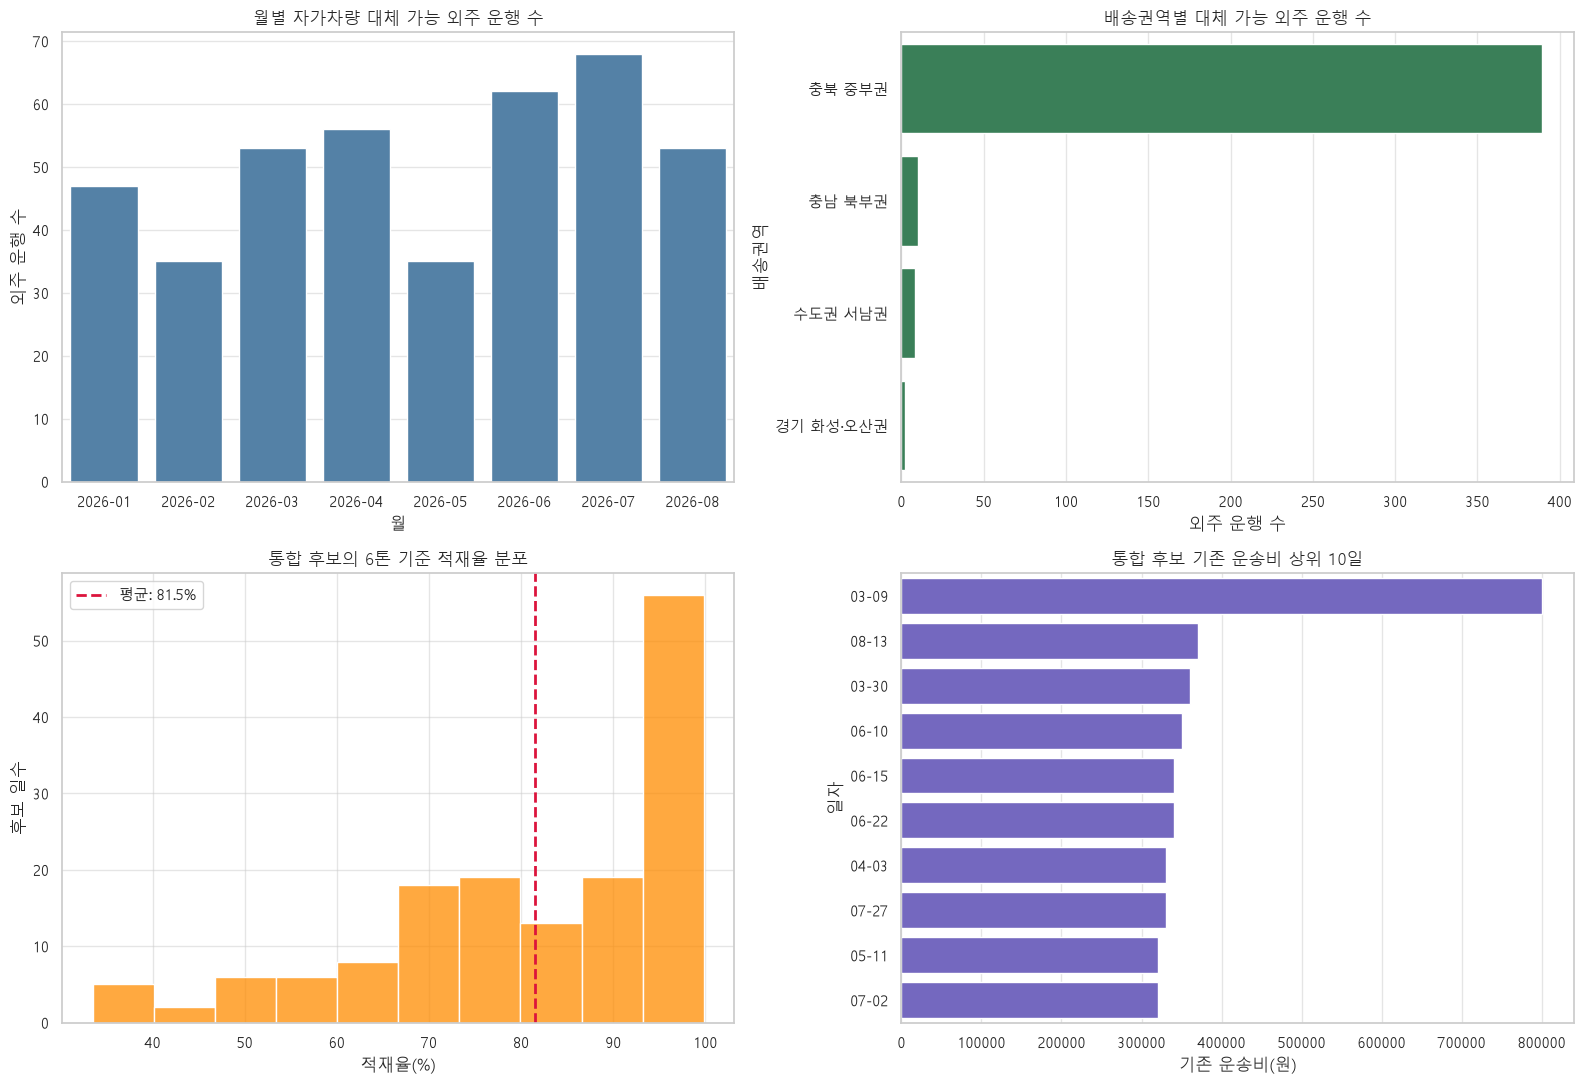

[1월 5일 후보 확인]


,일자,배송권역,기존운행ID,납품업체,소재지,기존외주운행수,통합운행수,차량움직임감소수,합계중량_kg,적재율_pct,기존운송비_원,월
0,2026-01-05,충북 중부권,"26-이-1-1, 26-이-1-2","토마스, 일산","충북 청주, 충북 음성",2,1,1,4285.5,71.425,190000.0,2026-01


[후보 제외 현황]


,운행 수
전체 운행,879
복수 권역 운행으로 제외,32
중량 결측 또는 0으로 제외,17
6톤 초과로 제외,0


In [22]:
# 3.5톤 자가차량(1회 최대 적재량 6톤) 통합 배송 후보 분석
# 주의: 지도 API와 납품시간 데이터가 없으므로 아래 결과는 '확정 노선'이 아닌 1차 후보입니다.
from itertools import combinations
from IPython.display import display

MAX_LOAD_KG = 6_000

# 인접 배송지를 하나의 권역으로 묶습니다. 필요하면 실무 지식에 맞게 수정하세요.
# 명시되지 않은 소재지는 소재지 자체를 하나의 독립 권역으로 사용합니다.
region_map = {
    "충북 음성": "충북 중부권",
    "충북 진천": "충북 중부권",
    "충북 청주": "충북 중부권",
    "충남 천안": "충남 북부권",
    "충남 아산": "충남 북부권",
    "경기 화성": "경기 화성·오산권",
    "경기 오산": "경기 화성·오산권",
    "경기 시흥": "수도권 서남권",
    "경기 인천": "수도권 서남권",
    "경기 부천": "수도권 서남권",
    "경기 군포": "수도권 서남권",
    "서울 구로": "수도권 서남권",
    "서울 금천": "수도권 서남권",
}

required_columns = {
    "운행ID", "일자", "납품업체", "수량(kg)",
    "금액(원)", "소재지", "거리_km"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise KeyError(f"분석에 필요한 컬럼이 없습니다: {sorted(missing_columns)}")

route_source = df.copy()
route_source["일자"] = pd.to_datetime(route_source["일자"])
route_source["수량(kg)"] = pd.to_numeric(route_source["수량(kg)"], errors="coerce")
route_source["금액(원)"] = pd.to_numeric(route_source["금액(원)"], errors="coerce")
route_source["거리_km"] = pd.to_numeric(route_source["거리_km"], errors="coerce")
route_source["소재지"] = route_source["소재지"].astype("string").str.strip()
route_source["배송권역"] = (
    route_source["소재지"].map(region_map).fillna(route_source["소재지"])
)

def join_unique(series):
    values = pd.Series(series).dropna().astype(str).str.strip()
    return ", ".join(pd.unique(values[values.ne("")]))

# 기존 외주 운행 단위 자료: 한 운행에 이미 여러 납품처가 있으면 한 건으로 유지합니다.
route_trip = (
    route_source.groupby(["운행ID", "일자"], as_index=False)
                .agg(
                    납품업체=("납품업체", join_unique),
                    소재지=("소재지", join_unique),
                    배송권역=("배송권역", join_unique),
                    권역수=("배송권역", "nunique"),
                    중량_kg=("수량(kg)", "max"),
                    운송비_원=("금액(원)", "max"),
                    회사거리_km=("거리_km", "max"),
                )
)

# 한 운행이 여러 권역에 걸치거나 중량이 없으면 보수적으로 후보에서 제외합니다.
eligible_trip = route_trip.loc[
    route_trip["권역수"].eq(1)
    & route_trip["배송권역"].ne("")
    & route_trip["중량_kg"].gt(0)
    & route_trip["중량_kg"].le(MAX_LOAD_KG)
].copy()

# 날짜·권역별로 6톤 이하인 조합을 모두 비교하여 운행 수가 가장 많은 조합을 선택합니다.
# 운행 수가 같으면 기존 운송비가 큰 조합을 우선합니다.
region_candidates = []
for (date, region), group in eligible_trip.groupby(["일자", "배송권역"]):
    records = group.to_dict("records")
    if len(records) < 2:
        continue

    best = None
    best_score = None
    for size in range(2, len(records) + 1):
        for combo in combinations(records, size):
            total_weight = sum(item["중량_kg"] for item in combo)
            if total_weight > MAX_LOAD_KG:
                continue

            total_cost = sum(item["운송비_원"] for item in combo)
            score = (size, total_cost, total_weight)
            if best_score is None or score > best_score:
                best_score = score
                best = combo

    if best is not None:
        region_candidates.append({
            "일자": date,
            "배송권역": region,
            "기존운행ID": ", ".join(item["운행ID"] for item in best),
            "납품업체": ", ".join(item["납품업체"] for item in best),
            "소재지": ", ".join(dict.fromkeys(item["소재지"] for item in best)),
            "기존외주운행수": len(best),
            "통합운행수": 1,
            "차량움직임감소수": len(best) - 1,
            "합계중량_kg": sum(item["중량_kg"] for item in best),
            "적재율_pct": sum(item["중량_kg"] for item in best) / MAX_LOAD_KG * 100,
            "기존운송비_원": sum(item["운송비_원"] for item in best),
        })

region_candidates = pd.DataFrame(region_candidates)

if region_candidates.empty:
    print("현재 권역 및 6톤 조건을 만족하는 통합 후보가 없습니다.")
    selected_routes = region_candidates.copy()
else:
    # 자가차량 1대·하루 1회 운행을 가정하여 날짜별 최우선 후보 하나만 선택합니다.
    selected_routes = (
        region_candidates.sort_values(
            ["일자", "기존외주운행수", "기존운송비_원", "합계중량_kg"],
            ascending=[True, False, False, False],
        )
        .drop_duplicates("일자", keep="first")
        .sort_values("일자")
        .reset_index(drop=True)
    )

    total_trips = route_trip["운행ID"].nunique()
    replaced_external_trips = selected_routes["기존외주운행수"].sum()
    reduced_vehicle_movements = selected_routes["차량움직임감소수"].sum()

    consolidation_summary = pd.Series({
        "전체 외주 운행 수": total_trips,
        "통합 배송 가능 일수": selected_routes["일자"].nunique(),
        "자가차량으로 대체 가능한 외주 운행 수": replaced_external_trips,
        "필요한 자가차량 통합 운행 수": len(selected_routes),
        "전체 차량 움직임 감소 수": reduced_vehicle_movements,
        "전체 외주 운행 중 대체 후보 비율(%)": replaced_external_trips / total_trips * 100,
        "통합 노선 평균 적재율(%)": selected_routes["적재율_pct"].mean(),
        "통합 후보 기존 운송비 합계(원)": selected_routes["기존운송비_원"].sum(),
    })

    summary_descriptions = {
        "전체 외주 운행 수": "분석 기간에 실제로 사용한 1톤 외주 용차의 전체 운행 횟수",
        "통합 배송 가능 일수": "같은 날·같은 권역·합계 6톤 이하 조건을 만족한 날짜 수(차량 1대, 하루 1회 기준)",
        "자가차량으로 대체 가능한 외주 운행 수": "선택된 통합 노선에 포함되어 3.5톤 자가차량으로 대체 가능한 기존 외주 운행 횟수",
        "필요한 자가차량 통합 운행 수": "대체 후보 외주 운행을 처리하기 위해 3.5톤 자가차량이 운행해야 하는 횟수",
        "전체 차량 움직임 감소 수": "기존 외주 운행 수에서 자가차량 통합 운행 수를 뺀 순수 운행 횟수 감소분",
        "전체 외주 운행 중 대체 후보 비율(%)": "전체 외주 운행 가운데 자가차량 통합 배송 후보에 포함된 운행의 비율",
        "통합 노선 평균 적재율(%)": "선택된 통합 노선별 합계 중량을 최대 적재량 6,000kg으로 나눈 비율의 평균",
        "통합 후보 기존 운송비 합계(원)": "통합 후보에 포함된 기존 외주 운송비 합계이며 자가차량 운영비를 차감하기 전 금액",
    }
    summary_table = consolidation_summary.to_frame("값")
    summary_table["설명"] = summary_table.index.map(summary_descriptions)

    print("[통합 배송 후보 요약]")
    display(summary_table.style.format({"값": "{:,.1f}"}))

    print("[날짜별 선택 후보 상세]")
    display(
        selected_routes.head(10).style.format({
            "합계중량_kg": "{:,.1f}",
            "적재율_pct": "{:,.1f}",
            "기존운송비_원": "{:,.0f}",
        })
    )
    selected_routes.to_excel("배송통합후보.xlsx", index=False)

    # 월별 요약
    selected_routes["월"] = selected_routes["일자"].dt.to_period("M").astype(str)
    monthly_candidates = (
        selected_routes.groupby("월", as_index=False)
                       .agg(
                           통합후보일수=("일자", "nunique"),
                           대체가능외주운행수=("기존외주운행수", "sum"),
                           차량움직임감소수=("차량움직임감소수", "sum"),
                           기존운송비_원=("기존운송비_원", "sum"),
                           평균적재율_pct=("적재율_pct", "mean"),
                       )
    )
    display(monthly_candidates.style.format({
        "기존운송비_원": "{:,.0f}",
        "평균적재율_pct": "{:,.1f}",
    }))

    # 시각화
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))

    sns.barplot(
        data=monthly_candidates, x="월", y="대체가능외주운행수",
        color="steelblue", ax=axes[0, 0],
    )
    axes[0, 0].set_title("월별 자가차량 대체 가능 외주 운행 수")
    axes[0, 0].set_xlabel("월")
    axes[0, 0].set_ylabel("외주 운행 수")

    region_summary = (
        selected_routes.groupby("배송권역")["기존외주운행수"]
                       .sum().sort_values(ascending=False).reset_index()
    )
    sns.barplot(
        data=region_summary, x="기존외주운행수", y="배송권역",
        color="seagreen", ax=axes[0, 1],
    )
    axes[0, 1].set_title("배송권역별 대체 가능 외주 운행 수")
    axes[0, 1].set_xlabel("외주 운행 수")
    axes[0, 1].set_ylabel("배송권역")

    sns.histplot(
        data=selected_routes, x="적재율_pct", bins=10,
        color="darkorange", edgecolor="white", ax=axes[1, 0],
    )
    axes[1, 0].axvline(
        selected_routes["적재율_pct"].mean(), color="crimson",
        linestyle="--", linewidth=2,
        label=f"평균: {selected_routes['적재율_pct'].mean():.1f}%",
    )
    axes[1, 0].set_title("통합 후보의 6톤 기준 적재율 분포")
    axes[1, 0].set_xlabel("적재율(%)")
    axes[1, 0].set_ylabel("후보 일수")
    axes[1, 0].legend()

    top_cases = selected_routes.nlargest(10, "기존운송비_원").sort_values("기존운송비_원", ascending=False)
    top_cases = top_cases.assign(표시일자=top_cases["일자"].dt.strftime("%m-%d"))
    sns.barplot(
        data=top_cases, x="기존운송비_원", y="표시일자",
        color="slateblue", ax=axes[1, 1],
    )
    axes[1, 1].set_title("통합 후보 기존 운송비 상위 10일")
    axes[1, 1].set_xlabel("기존 운송비(원)")
    axes[1, 1].set_ylabel("일자")
    axes[1, 1].ticklabel_format(style="plain", axis="x")

    plt.tight_layout()
    plt.show()

    # 검증용: 1월 5일 사례 및 후보 제외 현황
    print("[1월 5일 후보 확인]")
    display(selected_routes.loc[selected_routes["일자"].dt.strftime("%m-%d").eq("01-05")])

    quality_check = pd.Series({
        "전체 운행": len(route_trip),
        "복수 권역 운행으로 제외": route_trip["권역수"].gt(1).sum(),
        "중량 결측 또는 0으로 제외": route_trip["중량_kg"].isna().sum() + route_trip["중량_kg"].eq(0).sum(),
        "6톤 초과로 제외": route_trip["중량_kg"].gt(MAX_LOAD_KG).sum(),
    })
    print("[후보 제외 현황]")
    display(quality_check.to_frame("운행 수"))

In [24]:
dist_map = {
    "충북 음성": 10,
    "충북 진천": 15,
    "충북 청주": 30,
    "충남 천안": 47,
    "충남 아산": 110,
    "경기 화성": 90,
    "경기 오산": 70,
    "경기 시흥": 120,
    "경기 인천": 130,
    "경기 부천": 130,
    "경기 군포": 100,
    "서울 구로": 120,
    "서울 금천": 120,
}

# 3.5톤 자가차량 1회 왕복 운행비 추정 가정 (필요하면 실제 계약/회계 수치로 수정)
DIESEL_PRICE_KRW_L = 1_600       # 경유 단가(원/L)
FUEL_ECONOMY_KM_L = 7.0          # 3.5톤 차량 혼합 실연비(km/L)
VEHICLE_COST_KRW_KM = 250        # 감가상각·보험·정비·타이어 등(원/km)
TOLL_AND_MISC_KRW_KM = 80        # 통행료·기타 운행비 추정(원/km)
DRIVER_WAGE_KRW_H = 20_000       # 운전자 총 인건비(원/h)
AVERAGE_SPEED_KM_H = 45          # 상하차/도심 주행을 감안한 평균속도(km/h)
LOAD_UNLOAD_H_PER_STOP = 0.5     # 납품처별 상하차 시간(h)
MIN_WORK_H = 2.0                 # 배차·점검 포함 최소 인정시간(h)
MAX_35_LOAD_KG = 6_000           # 3.5톤 차량 최대 적재량(kg)

def _destinations(value):
    return [place.strip() for place in str(value).split(",") if place.strip()]

def _one_way_distance(value):
    distances = [dist_map.get(place) for place in _destinations(value)]
    known = [distance for distance in distances if distance is not None]
    return max(known) if known and len(known) == len(distances) else float("nan")

# 다중 경유 노선은 상세 주소/순서가 없으므로 가장 먼 납품처까지의 거리 × 2를 왕복거리로 봅니다.
selected_routes["편도거리_km"] = selected_routes["소재지"].apply(_one_way_distance)
selected_routes["예상왕복거리_km"] = selected_routes["편도거리_km"] * 2
selected_routes["납품처수"] = selected_routes["소재지"].apply(lambda x: len(_destinations(x)))
selected_routes["예상운행시간_h"] = (
    selected_routes["예상왕복거리_km"] / AVERAGE_SPEED_KM_H
    + selected_routes["납품처수"] * LOAD_UNLOAD_H_PER_STOP
).clip(lower=MIN_WORK_H)
selected_routes["예상유류비_원"] = (
    selected_routes["예상왕복거리_km"] / FUEL_ECONOMY_KM_L * DIESEL_PRICE_KRW_L
)
selected_routes["예상차량유지비_원"] = (
    selected_routes["예상왕복거리_km"] * VEHICLE_COST_KRW_KM
)
selected_routes["예상통행기타비_원"] = (
    selected_routes["예상왕복거리_km"] * TOLL_AND_MISC_KRW_KM
)
selected_routes["예상인건비_원"] = (
    selected_routes["예상운행시간_h"] * DRIVER_WAGE_KRW_H
)
selected_routes["예상총운행비_원"] = selected_routes[[
    "예상유류비_원", "예상차량유지비_원", "예상통행기타비_원", "예상인건비_원"
]].sum(axis=1, min_count=4)
selected_routes["3.5톤_운행가능"] = selected_routes["합계중량_kg"] <= MAX_35_LOAD_KG
selected_routes["예상절감액_원"] = (
    selected_routes["기존운송비_원"] - selected_routes["예상총운행비_원"]
).where(selected_routes["3.5톤_운행가능"])
selected_routes["예상절감률_pct"] = (
    selected_routes["예상절감액_원"] / selected_routes["기존운송비_원"] * 100
)

cost_columns = [
    "일자", "소재지", "합계중량_kg", "3.5톤_운행가능", "기존운송비_원",
    "예상왕복거리_km", "예상유류비_원", "예상차량유지비_원",
    "예상통행기타비_원", "예상인건비_원", "예상총운행비_원",
    "예상절감액_원", "예상절감률_pct",
]
display(selected_routes.head(10)[cost_columns].style.format({
    col: "{:,.0f}" for col in cost_columns if col.endswith("_원")
}).format({"예상왕복거리_km": "{:,.0f}", "예상절감률_pct": "{:,.1f}"}))

selected_routes.to_excel("예상비용절감률.xlsx", index=False)

,일자,소재지,합계중량_kg,3.5톤_운행가능,기존운송비_원,예상왕복거리_km,예상유류비_원,예상차량유지비_원,예상통행기타비_원,예상인건비_원,예상총운행비_원,예상절감액_원,예상절감률_pct
0,2026-01-05 00:00:00,"충북 청주, 충북 음성",4285.500000,True,190000.000000,60,13714.285714,15000,4800,46666.666667,80180.952381,109819.047619,57.8
1,2026-01-06 00:00:00,"충북 청주, 충북 진천, 충북 음성",5784.800000,True,280000.000000,60,13714.285714,15000,4800,56666.666667,90180.952381,189819.047619,67.8
2,2026-01-08 00:00:00,"충북 청주, 충북 음성",3720.000000,True,190000.000000,60,13714.285714,15000,4800,46666.666667,80180.952381,109819.047619,57.8
3,2026-01-09 00:00:00,"충북 청주, 충북 진천, 충북 음성",5724.500000,True,290000.000000,60,13714.285714,15000,4800,56666.666667,90180.952381,199819.047619,68.9
4,2026-01-12 00:00:00,"서울 구로, 경기 인천, 경기 부천",2343.500000,True,295000.000000,260,59428.571429,65000,20800,145555.555556,290784.126984,4215.873016,1.4
5,2026-01-13 00:00:00,충남 천안,3417.700000,True,200000.000000,94,21485.714286,23500,7520,51777.777778,104283.492063,95716.507937,47.9
6,2026-01-14 00:00:00,충남 천안,3267.600000,True,190000.000000,94,21485.714286,23500,7520,51777.777778,104283.492063,85716.507937,45.1
7,2026-01-15 00:00:00,"충북 진천, 충북 음성",3167.000000,True,140000.000000,30,6857.142857,7500,2400,40000.000000,56757.142857,83242.857143,59.5
8,2026-01-16 00:00:00,충남 천안,3624.100000,True,220000.000000,94,21485.714286,23500,7520,51777.777778,104283.492063,115716.507937,52.6
9,2026-01-19 00:00:00,충북 음성,5469.700000,True,200000.000000,20,4571.428571,5000,1600,40000.000000,51171.428571,148828.571429,74.4


In [25]:
# 3.5톤 통합 운행 비용 절감 요약
summary_base = selected_routes.copy()
summary_base["월"] = pd.to_datetime(summary_base["일자"]).dt.to_period("M").astype(str)
distance_missing = summary_base["예상왕복거리_km"].isna()
eligible = summary_base["3.5톤_운행가능"] & ~distance_missing
eligible_routes = summary_base.loc[eligible].copy()

eligible_existing_cost = eligible_routes["기존운송비_원"].sum()
eligible_operating_cost = eligible_routes["예상총운행비_원"].sum()
total_saving = eligible_routes["예상절감액_원"].sum()
total_saving_rate = total_saving / eligible_existing_cost * 100 if eligible_existing_cost else float("nan")

saving_summary = pd.Series({
    "전체 통합 후보 수": len(summary_base),
    "3.5톤 운행 가능 후보 수": int(eligible.sum()),
    "3.5톤 적재량 초과 후보 수": int((~summary_base["3.5톤_운행가능"]).sum()),
    "거리 정보 누락 후보 수": int(distance_missing.sum()),
    "절감 발생 후보 수": int((eligible_routes["예상절감액_원"] > 0).sum()),
    "비용 증가 후보 수": int((eligible_routes["예상절감액_원"] < 0).sum()),
    "운행 가능 후보 기존 운송비(원)": eligible_existing_cost,
    "예상 총 운행비(원)": eligible_operating_cost,
    "예상 총 절감액(원)": total_saving,
    "전체 예상 절감률(%)": total_saving_rate,
    "운행 1회당 평균 절감액(원)": eligible_routes["예상절감액_원"].mean(),
})

print("[3.5톤 통합 운행 비용 절감 요약]")
display(saving_summary.to_frame("값").style.format({"값": "{:,.1f}"}))

monthly_saving_summary = (
    eligible_routes.groupby("월", as_index=False)
    .agg(
        운행가능후보수=("일자", "size"),
        기존운송비_원=("기존운송비_원", "sum"),
        예상총운행비_원=("예상총운행비_원", "sum"),
        예상절감액_원=("예상절감액_원", "sum"),
    )
)
monthly_saving_summary["예상절감률_pct"] = (
    monthly_saving_summary["예상절감액_원"] / monthly_saving_summary["기존운송비_원"] * 100
)

print("[월별 비용 절감 요약]")
display(monthly_saving_summary.style.format({
    "기존운송비_원": "{:,.0f}",
    "예상총운행비_원": "{:,.0f}",
    "예상절감액_원": "{:,.0f}",
    "예상절감률_pct": "{:,.1f}",
}))

[3.5톤 통합 운행 비용 절감 요약]


,값
전체 통합 후보 수,152.0
3.5톤 운행 가능 후보 수,152.0
3.5톤 적재량 초과 후보 수,0.0
거리 정보 누락 후보 수,0.0
절감 발생 후보 수,150.0
비용 증가 후보 수,2.0
운행 가능 후보 기존 운송비(원),"34,485,000.0"
예상 총 운행비(원),"10,867,757.8"
예상 총 절감액(원),"23,617,242.2"
전체 예상 절감률(%),68.5


[월별 비용 절감 요약]


,월,운행가능후보수,기존운송비_원,예상총운행비_원,예상절감액_원,예상절감률_pct
0,2026-01,19,"3,975,000","1,576,435","2,398,565",60.3
1,2026-02,14,"2,835,000","1,140,749","1,694,251",59.8
2,2026-03,20,"5,035,000","1,319,110","3,715,890",73.8
3,2026-04,21,"4,250,000","1,300,010","2,949,990",69.4
4,2026-05,13,"2,860,000","769,014","2,090,986",73.1
5,2026-06,24,"5,395,000","2,108,968","3,286,032",60.9
6,2026-07,23,"5,510,000","1,382,262","4,127,738",74.9
7,2026-08,18,"4,625,000","1,271,211","3,353,789",72.5
